In [1]:
import numpy as np, pandas as pd
import seaborn as sns, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, kruskal, spearmanr, shapiro
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm


In [2]:
win2 = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/improving models/outputs2/windows_with_animation_details2.csv")


[Task 2.x] ease: built Δ rows = 199

[Task 2.x] ease: Kruskal–Wallis (top by p)
property               feature        H     p_kw  k_levels
    ease    saccade_rate_per_s 4.123839 0.042283         2
    ease       dir_change_rate 3.771382 0.052137         2
    ease     x_dir_change_rate 3.482445 0.062023         2
    ease        fix_rate_per_s 2.946546 0.086061         2
    ease            left_ratio 1.124730 0.288902         2
    ease      saccade_mean_mag 0.379822 0.537698         2
    ease            axis_ratio 0.361821 0.547497         2
    ease           right_ratio 0.135806 0.712487         2
    ease        fix_median_dur 0.133161 0.715176         2
    ease gaze_dispersion_total 0.043441 0.834898         2

[Task 2.x] ease: Pairwise (FDR) — top
              feature level_a  level_b  diff_mean  effect_delta    p_raw  p_fdr  n_a  n_b
       fix_rate_per_s Ease-in Ease-out  -0.155682      0.148581 0.086309    NaN   96   91
       fix_median_dur Ease-in Ease-out   0.016471  

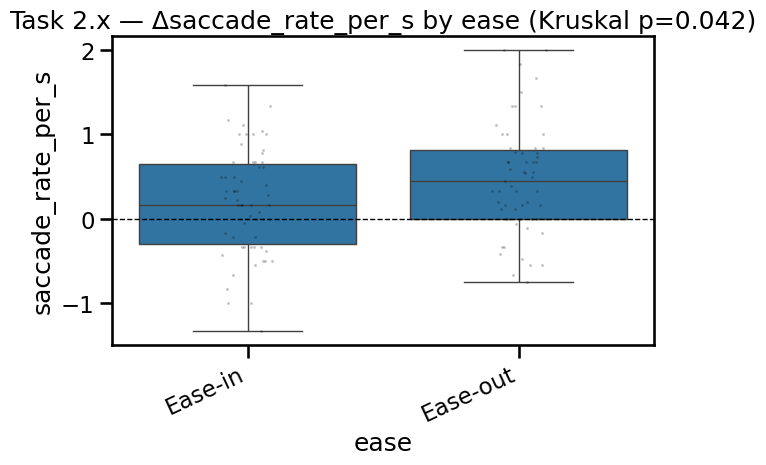


[Task 2.x] direction: built Δ rows = 199

[Task 2.x] direction: Kruskal–Wallis (top by p)
 property            feature        H     p_kw  k_levels
direction     fix_median_dur 6.902880 0.031700         3
direction  x_dir_change_rate 4.833948 0.089191         3
direction         left_ratio 4.375626 0.112162         3
direction   saccade_mean_mag 3.222980 0.199590         3
direction         axis_ratio 1.924375 0.382056         3
direction             x_mean 1.514454 0.468965         3
direction saccade_rate_per_s 1.291027 0.524393         3
direction          x_entropy 1.100337 0.576853         3
direction    dir_change_rate 0.947608 0.622629         3
direction        right_ratio 0.576094 0.749726         3

[Task 2.x] direction: Pairwise (FDR) — top
          feature       level_a       level_b   diff_mean  effect_delta    p_raw    p_fdr  n_a  n_b
   fix_median_dur Left to Right       Pulsing    0.092136     -0.350679 0.008895 0.026685   26   68
   fix_median_dur      Bouncing Left t

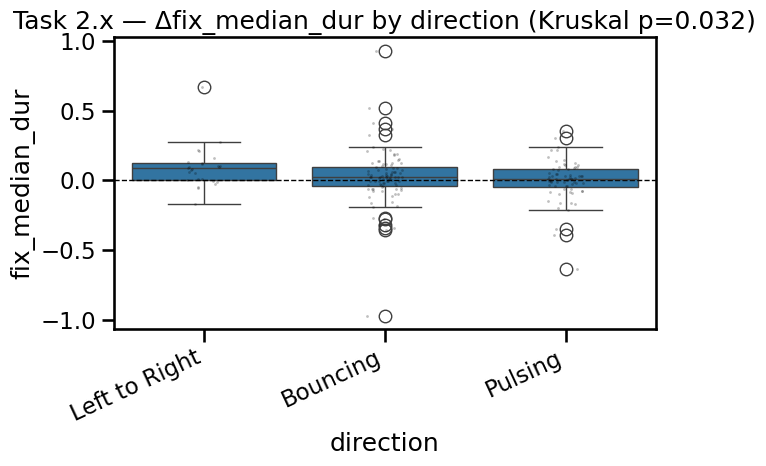


[Task 2.x] delay: built Δ rows = 199

[Task 2.x] delay: Spearman (top by p)
              feature  spearman_rho  p_spearman   n
       fix_median_dur     -0.064194    0.382742 187
      dir_change_rate     -0.067967    0.458856 121
gaze_dispersion_total      0.047562    0.519149 186
       fix_rate_per_s      0.047059    0.522459 187
          right_ratio      0.050726    0.580570 121
               x_mean      0.035522    0.698898 121
   saccade_rate_per_s     -0.032216    0.725745 121
            x_entropy      0.028894    0.753065 121
     saccade_mean_mag     -0.018228    0.804434 187
    x_dir_change_rate     -0.019833    0.830475 119

[Task 2.x] delay: OLS (top by p)
              feature  beta_delay   p_beta   n
     saccade_mean_mag -371.646557 0.091370 187
       fix_rate_per_s    0.152744 0.224262 187
            x_entropy    0.036154 0.744834 121
gaze_dispersion_total   -0.036746 0.748952 186
      dir_change_rate   -0.299541 0.762016 121
   saccade_rate_per_s   -0.043874 0

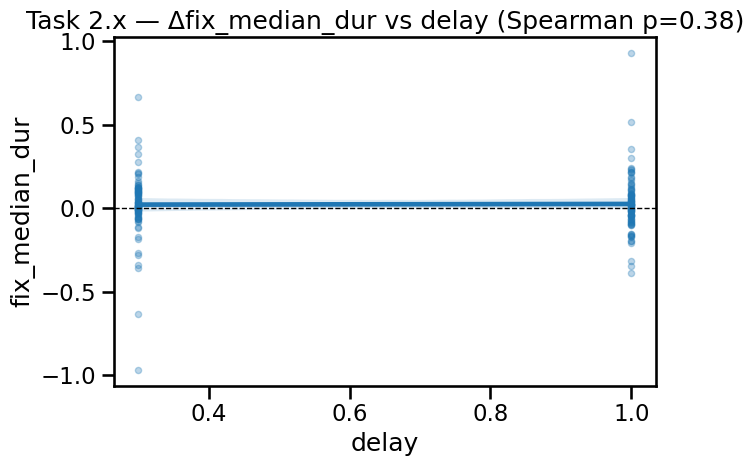

In [3]:
# =============================================
# Per-trial Δ(ON_level − OFF) by animation property
# =============================================

sns.set_context("talk")

# ------- config -------
FEATS = [
    'fix_rate_per_s','fix_median_dur',
    'gaze_dispersion_total',
    'saccade_mean_mag','saccade_rate_per_s',
    'dir_change_rate','axis_ratio',
    'dwell_text_ratio','dwell_map_ratio','aoi_entropy',
    'trans_text_to_map','trans_map_to_text',
    'x_mean','x_dir_change_rate','left_ratio','right_ratio','x_entropy'
]
ID_COLS = ["Video Name (folder)","User ID (file)","Task Id"]
PROP_CATS = ["ease","direction"]   # categorical properties
PROP_DELAY = "delay"               # numeric-like (we’ll parse)

MIN_ON_PER_LEVEL = 15   # skip underpowered levels
ALPHA = 0.05
PLOT = True

# ------- small helpers -------
def _normal(x, alpha=0.05, max_n=5000):
    x = pd.Series(x, dtype="float64").dropna()
    if len(x) < 3: return False
    x = x.sample(min(len(x), max_n), random_state=0)
    try:
        _, p = shapiro(x)
        return p > alpha
    except Exception:
        return False

def _cliffs_delta(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    if len(a) == 0 or len(b) == 0: return np.nan
    a_sorted, b_sorted = np.sort(a), np.sort(b)
    i=j=gt=lt=0
    na, nb = len(a_sorted), len(b_sorted)
    while i < na and j < nb:
        if a_sorted[i] > b_sorted[j]:
            lt += (na - i); j += 1
        elif a_sorted[i] < b_sorted[j]:
            gt += (nb - j); i += 1
        else:
            ai=i; bj=j
            while ai<na and a_sorted[ai]==a_sorted[i]: ai+=1
            while bj<nb and b_sorted[bj]==b_sorted[j]: bj+=1
            i, j = ai, bj
    return (gt - lt) / (na * nb)

def _parse_delay_series(s):
    """Turn strings like '0.3s' into float seconds; keep numeric as-is; return float series."""
    out = pd.to_numeric(s, errors="coerce")
    # try strings like '0.3s'
    need = out.isna() & s.notna()
    if need.any():
        ss = s[need].astype(str).str.strip().str.lower().str.replace("s","", regex=False)
        out.loc[need] = pd.to_numeric(ss, errors="coerce")
    return out.astype("float64")

# ------- core: build Δ per trial per property level -------
def build_deltas_by_property(win: pd.DataFrame, property_col: str, prefer_off_pre: bool = False) -> pd.DataFrame:
    """
    For each trial (Video, User, Task Id):
      - OFF baseline = mean of OFF windows (optionally prefer phase=='OFF_PRE' if available & non-empty).
      - For each ON level of `property_col` in that trial:
          Δ_f(level) = mean(ON windows with that level) - mean(OFF baseline)
    Returns one row per (trial × level) with Δ for all FEATS + the level value.
    """
    df = win.copy()
    # tidy labels & props
    df["label"] = df["label"].astype(str).str.upper().str.strip()
    if property_col not in df.columns:
        raise KeyError(f"Property '{property_col}' not found in dataframe.")
    if property_col == PROP_DELAY:
        df[property_col] = _parse_delay_series(df[property_col])
    else:
        df[property_col] = df[property_col].astype(str).str.strip()

    # keep ON/OFF rows only, and rows that have at least one feature
    df = df[df["label"].isin(["ON","OFF"])].copy()
    if "phase" in df.columns and prefer_off_pre:
        has_pre = df[df["label"]=="OFF"]["phase"].astype(str).str.upper().eq("OFF_PRE").any()

    rows = []
    for keys, grp in df.groupby(ID_COLS, dropna=False):
        g_off = grp[grp["label"]=="OFF"]
        if g_off.empty:
            continue
        # prefer OFF_PRE if requested & present
        if prefer_off_pre and "phase" in g_off.columns:
            g_pre = g_off[g_off["phase"].astype(str).str.upper().eq("OFF_PRE")]
            if not g_pre.empty:
                g_off = g_pre

        off_mean = {f: g_off[f].mean() if f in g_off else np.nan for f in FEATS}

        g_on = grp[grp["label"]=="ON"]
        if g_on.empty:
            continue

        # levels within this trial
        levels = g_on[property_col].dropna().unique().tolist()
        if len(levels) == 0:
            continue

        for lvl in levels:
            sel = g_on[g_on[property_col] == lvl]
            if sel.empty: 
                continue
            on_mean = {f: sel[f].mean() if f in sel else np.nan for f in FEATS}
            d = {ID_COLS[0]: keys[0], ID_COLS[1]: keys[1], ID_COLS[2]: keys[2],
                 property_col: lvl}
            # Δ = ON(level) − OFF(baseline)
            for f in FEATS:
                d[f] = on_mean.get(f, np.nan) - off_mean.get(f, np.nan)
            rows.append(d)

    out = pd.DataFrame(rows)
    return out

# ------- stats: categorical property (ease / direction) -------
def analyze_categorical_property(delta_df: pd.DataFrame, property_col: str, title: str):
    dd = delta_df.copy()
    dd = dd.dropna(subset=[property_col]).copy()
    # retain only levels with enough trials
    lvl_counts = dd[property_col].value_counts()
    keep_lvls = lvl_counts[lvl_counts >= MIN_ON_PER_LEVEL].index.tolist()
    dd = dd[dd[property_col].isin(keep_lvls)].copy()
    if dd.empty or len(keep_lvls) < 2:
        print(f"[{title}] {property_col}: not enough usable levels (kept {len(keep_lvls)}).")
        return None, None

    # Kruskal across levels + pairwise MW with FDR, per feature
    kw_rows, pw_rows = [], []

    for f in FEATS:
        if f not in dd.columns: 
            continue
        groups = [g[f].dropna().values for _, g in dd.groupby(property_col)]
        # need at least 2 non-empty groups
        usable = [len(g) for g in groups if len(g) > 0]
        if len(usable) < 2:
            continue

        # Kruskal–Wallis
        try:
            H, p_kw = kruskal(*groups)
        except ValueError:
            # happens if all values identical
            H, p_kw = np.nan, np.nan
        kw_rows.append({"property": property_col, "feature": f, "H": H, "p_kw": p_kw,
                        "k_levels": len(keep_lvls)})

        # Pairwise (Mann–Whitney) with FDR across pairs for this feature
        levels = list(dd[property_col].unique())
        levels.sort()
        records = []
        for i in range(len(levels)):
            for j in range(i+1, len(levels)):
                L1, L2 = levels[i], levels[j]
                x = dd.loc[dd[property_col]==L1, f].dropna().values
                y = dd.loc[dd[property_col]==L2, f].dropna().values
                if len(x) < MIN_ON_PER_LEVEL or len(y) < MIN_ON_PER_LEVEL: 
                    continue
                try:
                    stat, p = mannwhitneyu(x, y, alternative="two-sided")
                except ValueError:
                    p = np.nan
                eff = _cliffs_delta(x, y)
                records.append({"property": property_col, "feature": f,
                                "level_a": L1, "level_b": L2,
                                "n_a": len(x), "n_b": len(y),
                                "diff_mean": float(np.nanmean(x) - np.nanmean(y)),
                                "p_raw": p, "effect_delta": eff})
        if records:
            dfp = pd.DataFrame(records)
            if dfp["p_raw"].notna().sum() >= 2:
                rej, p_adj, _, _ = multipletests(dfp["p_raw"].fillna(1.0), method="fdr_bh")
                dfp["p_fdr"] = p_adj
                dfp["sig"] = rej
            else:
                dfp["p_fdr"] = np.nan; dfp["sig"] = False
            pw_rows.append(dfp)

    kw_df = pd.DataFrame(kw_rows)
    pw_df = pd.concat(pw_rows, ignore_index=True) if pw_rows else pd.DataFrame()

    # Quick print
    if not kw_df.empty:
        top_kw = kw_df.sort_values("p_kw").head(10)
        print(f"\n[{title}] {property_col}: Kruskal–Wallis (top by p)")
        print(top_kw.to_string(index=False))
    if not pw_df.empty:
        top_pw = pw_df.sort_values("p_fdr").head(10)
        print(f"\n[{title}] {property_col}: Pairwise (FDR) — top")
        print(top_pw[["feature","level_a","level_b","diff_mean","effect_delta","p_raw","p_fdr","n_a","n_b"]]
              .to_string(index=False))

    # Optional plot: per-level box for the best feature
    if PLOT and not kw_df.empty:
        best_feat = kw_df.loc[kw_df["p_kw"].idxmin(), "feature"]
        plt.figure(figsize=(7,5))
        sns.boxplot(data=dd, x=property_col, y=best_feat)
        sns.stripplot(data=dd, x=property_col, y=best_feat, color="k", alpha=0.25, size=2)
        plt.axhline(0, ls="--", lw=1, c="k")
        plt.title(f"{title} — Δ{best_feat} by {property_col} (Kruskal p={kw_df['p_kw'].min():.2g})")
        plt.xticks(rotation=25, ha="right")
        plt.tight_layout(); plt.show()

    return kw_df, pw_df

# ------- stats: numeric delay (correlation + OLS) -------
def analyze_delay_property(delta_df: pd.DataFrame, title: str):
    if PROP_DELAY not in delta_df.columns:
        print(f"[{title}] delay column not found.")
        return None, None
    dd = delta_df.dropna(subset=[PROP_DELAY]).copy()
    if dd.empty:
        print(f"[{title}] No usable delay values.")
        return None, None

    corr_rows, ols_rows = [], []
    for f in FEATS:
        if f not in dd.columns: 
            continue
        x = dd[PROP_DELAY].astype(float).values
        y = dd[f].astype(float).values
        mask = np.isfinite(x) & np.isfinite(y)
        x, y = x[mask], y[mask]
        if len(x) < 30:
            continue
        # Spearman correlation (robust to non-normal)
        rho, p = spearmanr(x, y)
        corr_rows.append({"feature": f, "spearman_rho": rho, "p_spearman": p, "n": len(x)})

        # OLS (simple) with robust SE
        X = sm.add_constant(x)
        model = sm.OLS(y, X, missing="drop").fit(cov_type="HC3")
        b1 = model.params[1]; p_b1 = model.pvalues[1]
        ols_rows.append({"feature": f, "beta_delay": b1, "p_beta": p_b1, "n": len(x)})

    corr_df = pd.DataFrame(corr_rows)
    ols_df = pd.DataFrame(ols_rows)

    if not corr_df.empty:
        top = corr_df.sort_values("p_spearman").head(10)
        print(f"\n[{title}] delay: Spearman (top by p)")
        print(top.to_string(index=False))
    if not ols_df.empty:
        top = ols_df.sort_values("p_beta").head(10)
        print(f"\n[{title}] delay: OLS (top by p)")
        print(top.to_string(index=False))

    # Optional plot: best feature vs delay
    if PLOT and not corr_df.empty:
        best_feat = corr_df.loc[corr_df["p_spearman"].idxmin(), "feature"]
        plt.figure(figsize=(7,5))
        sns.regplot(data=dd, x=PROP_DELAY, y=best_feat, scatter_kws=dict(alpha=0.3, s=20))
        plt.axhline(0, ls="--", lw=1, c="k")
        plt.title(f"{title} — Δ{best_feat} vs delay (Spearman p={corr_df['p_spearman'].min():.2g})")
        plt.tight_layout(); plt.show()

    return corr_df, ols_df

# ------- master runner per dataset -------
def run_property_vs_off(win_df: pd.DataFrame, title: str, prefer_off_pre: bool = False):
    results = {}

    # Categorical properties: build Δ table then analyze
    for prop in [p for p in PROP_CATS if p in win_df.columns]:
        deltas_prop = build_deltas_by_property(win_df, prop, prefer_off_pre=prefer_off_pre)
        print(f"\n[{title}] {prop}: built Δ rows = {len(deltas_prop)}")
        if deltas_prop.empty:
            continue
        kw_df, pw_df = analyze_categorical_property(deltas_prop, prop, title)
        results[f"{prop}_deltas"] = deltas_prop
        results[f"{prop}_kw"] = kw_df
        results[f"{prop}_pairwise"] = pw_df

    # Numeric delay (if present / parseable)
    if PROP_DELAY in win_df.columns:
        deltas_delay = build_deltas_by_property(win_df, PROP_DELAY, prefer_off_pre=prefer_off_pre)
        print(f"\n[{title}] delay: built Δ rows = {len(deltas_delay)}")
        if not deltas_delay.empty:
            corr_df, ols_df = analyze_delay_property(deltas_delay, title)
            results["delay_deltas"] = deltas_delay
            results["delay_corr"] = corr_df
            results["delay_ols"] = ols_df

    return results

# =========================
# HOW TO RUN (three datasets)
# =========================
# Example variables you already have:
#   win_task1, win_task2, win_task3
# Each is a windows table (one animation family), with FEATS + 'label' + properties.

res2 = run_property_vs_off(win2, "Task 2.x", prefer_off_pre=True)

# Optionally save key outputs
# if "ease_deltas" in res1:  res1["ease_deltas"].to_csv("outputs/task1_ease_deltas.csv", index=False)
# if "direction_pairwise" in res1: res1["direction_pairwise"].to_csv("outputs/task1_direction_pairwise.csv", index=False)